# Import and fit a Carterra single-cycle titration

Import **`carterra_rows.csv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it uses pyKinGenie's one-site fitter and compares its output with the author report. No data download is required.

**Data origin:** [Duke TitrationAnalysis Carterra workbook](https://github.com/DukeCHSI/TitrationAnalysis/tree/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra). TitrationAnalysis tool, Kan Li and S Moses Dennison, Duke University. [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/TitrationAnalysis-LICENSE).

**Timing limitation:** the 1140 s cycle period is reconstructed from nominal protocol durations. An absolute injection log was not available. The fitted kinetic constants are conditional on this assumption; the notebook is not an exact reproduction of the published analysis.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import display

# Works from the repository root, notebooks/ or docs/notebooks/.
repo_root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p / "src" / "pykingenie").is_dir())
sys.path[:0] = [str(repo_root / "src"), str(repo_root / "notebooks")]

from pykingenie import KineticsAnalyzer, read_info_sheet
from pykingenie.utils.plotting import plot_association_dissociation, plot_traces_all
from notebook_helpers import show_plotly_static

data_folder = repo_root / "notebooks" / "data" / "spr_exports"
fit_metadata = json.loads((data_folder / "fit_metadata.json").read_text())

## File layout and single-cycle import

The CSV retains **all 13 injections** for one physical sensor (Block 1/A1/ROI 1),
worksheet rows 2–14, in their original acquisition order. The five concentrations
on page 1 of the author fit report are injections **9–13** (worksheet rows 10–14):
**62.5, 125, 250, 500, 1000 nM**. Earlier injections are retained for the initial
alignment and chronological context; the comparison fit still selects five.

Use `single_cycle=True, cycle_duration=1140` to combine the row-wise exports into
one sensor with **27 steps**: baseline, association, dissociation, association,
dissociation, ... . Each following pre-association baseline extends the preceding
dissociation because analyte is absent during that interval. Responses are not
shifted or interpolated during import, and source labels are retained in
`ligand_conc_df["Source_curve"]`.

**Clock assumption:** 1140 s is the nominal sum of the source sheet's baseline
120 s, association 300 s and fitted dissociation 720 s. This is an explicit
protocol-based reconstruction, not a recovered absolute injection log. Use the
actual cycle period when available. The source excerpts retain all finite points
in each row's 0–1140 s window; their later export tails are omitted and recorded
in the manifest. No response is smoothed or replaced.

## Import with the companion Data Info Sheet

The TitrationAnalysis sample sheet that accompanies the export supplies the
association window (`Bsl Start` + `Baseline`, then `Association`), the molar
concentrations and the analyte (`sample_id`). `read_info_sheet` shows how pyKinGenie
reads it.

Its included rows (A1, A5, A9) share the same timing and concentrations. The
cycle period, Baseline + Association + Dissociation = 1140 s, rebuilds the
single-cycle clock. Curves outside the sheet's *Incl. Conc.* start unselected
(`Select` column).

`pyKinetics.load` detects the file format (`carterra_csv`), reads the file with `CarterraExperiment.read_csv` and adds the experiment to the analyzer; the keyword options go to that reader.

In [2]:
data_file = data_folder / "carterra_rows.csv"
info_file = data_folder / "metadata" / "Example Data Info Sheet - Carterra.xlsx"

pyKinetics = KineticsAnalyzer()
experiment = pyKinetics.load(data_file, info=info_file, single_cycle=True)

display(pd.Series(experiment.exp_info["info_sheet"], name="Info sheet row"))
experiment.ligand_conc_df

Included                                                                           True
Block                                                                           1,2,3,4
Position                                                                             A1
Analyte                                                                         AE.A244
Ligand                                                                     CH31 10µg/ml
Baseline_start_s                                                                    0.0
Baseline_s                                                                        120.0
Association_s                                                                     300.0
Dissociation_s                                                                    720.0
Association_skip_s                                                                  0.0
Dissociation_skip_s                                                                 0.0
Concentrations_micromolar       

,Sensor,Analyte_location,Concentration_micromolar,SampleID,Replicate,Loading_location,Experiment,Select,Source_curve
0,single_cycle,1,0.000244,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 13] [NotFitted]
1,single_cycle,2,0.000488,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 12] [NotFitted]
2,single_cycle,3,0.000977,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 11] [NotFitted]
3,single_cycle,4,0.001950,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 10] [NotFitted]
4,single_cycle,5,0.003910,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 9] [NotFitted]
5,single_cycle,6,0.007810,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 8] [NotFitted]
6,single_cycle,7,0.015600,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 7] [NotFitted]
7,single_cycle,8,0.031300,AE.A244,1,0,carterra_rows,False,[Ligand 1-AE.A244 Conc. 6] [NotFitted]
8,single_cycle,9,0.062500,AE.A244,1,0,carterra_rows,True,[Ligand 1-AE.A244 Conc. 5] [NotFitted]
9,single_cycle,10,0.125000,AE.A244,1,0,carterra_rows,True,[Ligand 1-AE.A244 Conc. 4] [NotFitted]


All 13 rows become one sensor (`single_cycle`). The original row labels are kept in
`Source_curve`; `Analyte_location` numbers the injections in acquisition order.
Each later baseline belongs to the preceding dissociation, giving 13
association/dissociation pairs after one initial baseline.

In [3]:
experiment.df_steps

,#Step,Name,Type,Start,Column_location,Loading_location
0,1,Baseline,BASELINE,1.25,0,NaN
1,2,Association 1,ASSOC,120.00,1,0
2,3,Dissociation 1,DISASSOC,420.00,1,NaN
3,4,Association 2,ASSOC,1260.00,2,0
4,5,Dissociation 2,DISASSOC,1560.00,2,NaN
5,6,Association 3,ASSOC,2400.00,3,0
6,7,Dissociation 3,DISASSOC,2700.00,3,NaN
7,8,Association 4,ASSOC,3540.00,4,0
8,9,Dissociation 4,DISASSOC,3840.00,4,NaN
9,10,Association 5,ASSOC,4680.00,5,0


## Imported single-cycle sensorgram

All retained observations on the reconstructed protocol clock, before alignment.
The bound signal carries over from one injection to the next.

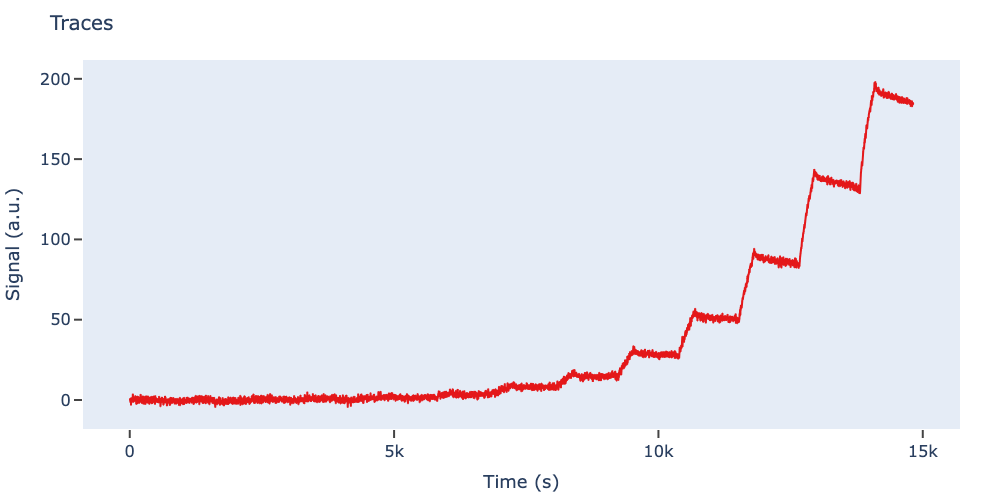

In [4]:
show_plotly_static(plot_traces_all(pyKinetics, pyKinetics.get_legends_table()),
                   width=1000, height=500, scale=1)

## Published one-site model

The original Carterra sample sheet specifies association **120–420 s**,
dissociation **420–1140 s**, no regeneration and no bulk shift. Fit a **one-site
Langmuir single-cycle model with local Smax using pyKinGenie**, comparing
with Block 1 / A1 / ROI 1, fitting #1 in the author report. Selected worksheet
rows **10–14** map to **0.0625, 0.125, 0.25, 0.5, 1.0 µM** by source row
order, matching page 1 of the author sensorgram report.

The importer now preserves a common clock and emits alternating `ASSOC` /
`DISASSOC` steps. `align_association` aligns only the first baseline; the existing
method skips later associations immediately following a dissociation. The
selected first injection already has bound material: the existing fitter
estimates its starting signal from that association. Subsequent injections
carry their bound signal from the preceding fitted dissociation. No custom
fitting function or per-injection reset is used.

Reference: [Li et al., TitrationAnalysis](https://pmc.ncbi.nlm.nih.gov/articles/PMC10667272/) and the [author report](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Report_Example.csv). The original CSV is included locally with provenance in [SOURCES.md](data/spr_exports/SOURCES.md).

This notebook fits the **same five concentration curves** as the author report,
within the same nominal protocol windows. No alternative models or model selection are run.

## Align and fit with `KineticsAnalyzer`

`align_association` subtracts the mean of the last 10 baseline points.
`generate_fittings` builds one fitter per sample, `submit_steady_state_fitting`
provides the starting values and `submit_kinetics_fitting` runs the one-site
association/dissociation model on every observation (`trim_time=0`).

The info sheet already selected the five published concentrations; the
fitter still carries the bound state through the full sequence.

In [5]:
experiment.align_association(npoints=10)

pyKinetics.merge_ligand_conc_df()
pyKinetics.generate_fittings(pyKinetics.combined_ligand_conc_df, trim_time=0)
pyKinetics.submit_steady_state_fitting()
pyKinetics.submit_kinetics_fitting(fitting_model="one_to_one", shared_smax=False)

pyKinetics.get_fitting_results()
pyKinetics.fit_params_kinetics_all

,Concentration [µM],Kd [µM],k_off [1/s],Smax,(Derived) k_on [1/µM/s],Name
0,0.0625,0.016424,0.000077,225.232448,0.004679,AE.A244
1,0.1250,0.016424,0.000077,188.911912,0.004679,AE.A244
2,0.2500,0.016424,0.000077,189.647429,0.004679,AE.A244
3,0.5000,0.016424,0.000077,198.084702,0.004679,AE.A244
4,1.0000,0.016424,0.000077,216.573531,0.004679,AE.A244


## Single-cycle one-site fit from pyKinGenie

The package's `plot_association_dissociation` displays observations and the
fitted curves. Its plotting budget limits displayed
points only; the fit uses all observations allowed by `trim_time`.

**Check the published figure:** [Author fitted-sensorgram PDF](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Sensorgram_Example.pdf).
Locate Block 1 / A1 / ROI 1, fitting #1; ligand CH31 10 µg/ml, analyte AE.A244. The same five concentrations are shown on **page 1** of that report.

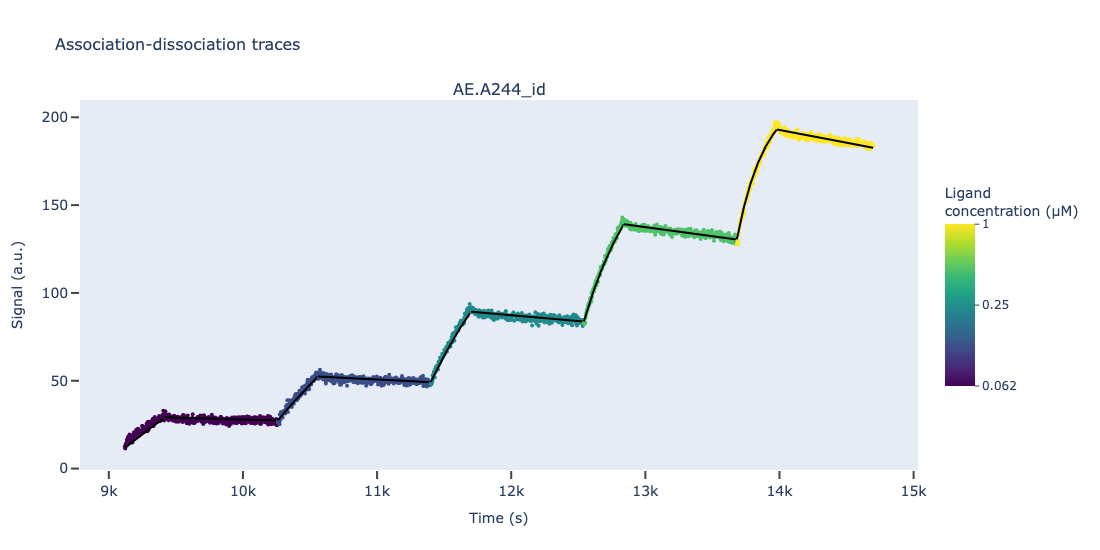

In [6]:
show_plotly_static(plot_association_dissociation(pyKinetics, split_by_smax_id=False),
                   width=1100, height=550, scale=1)

## Compare pyKinGenie's fitted parameters with the published values

The table uses `fitter.Kd` and `fitter.k_off` directly. kon is their ratio.
Only unit conversion and percentage differences are calculated below.
Local Smax values are shown in the library result table above.

**Check the published numbers:** [Original parameter table (PDF)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Report_Example.pdf) or [machine-readable values (CSV)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Report_Example.csv).
Use Block 1 / A1 / ROI 1, fitting #1; ligand CH31 10 µg/ml, analyte AE.A244. These are the values in the Published column below.

In [7]:
fitter = pyKinetics.fittings[pyKinetics.fittings_names[0]]
reference = fit_metadata[experiment.name]["literature_reference"]["parameters_molar"]

comparison = pd.DataFrame(
    {"Published": [reference["kon"], reference["koff"], reference["Kd"] * 1e9],
     "pyKinGenie": [fitter.k_off / fitter.Kd * 1e6, fitter.k_off, fitter.Kd * 1e3]},
    index=["kon (M⁻¹ s⁻¹)", "koff (s⁻¹)", "Kd (nM)"],
)
comparison["Difference (%)"] = 100 * (comparison["pyKinGenie"] / comparison["Published"] - 1)
comparison.style.format("{:.4g}")

,Published,pyKinGenie,Difference (%)
kon (M⁻¹ s⁻¹),5161,4679,-9.337
koff (s⁻¹),7.373e-05,7.685e-05,4.231
Kd (nM),14.29,16.42,14.97


## Scope of the comparison

The five author-selected concentrations are fitted using the existing
pyKinGenie single-cycle path. The response is no longer reset separately for
each injection. All subsequent selected associations carry state from a fitted
dissociation, including the intervening baseline wash.

The published and notebook fits still differ in initial-state estimation,
wash-window inclusion, sampling and fitting details. The reconstructed cycle
period is based on the source sheet, not an absolute acquisition log. The
comparison table reports the actual native-library results; it is not an exact
reproduction or validation of intrinsic kinetic constants.

See [SPR_FITTING.md](SPR_FITTING.md) for API calls and reference reports.